In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

print("Libraries imported successfully!")

uploaded = files.upload()
filename = next(iter(uploaded))

data = pd.read_csv(filename)

print("Dataset loaded successfully!")
print(data.head())
print("Dataset shape:", data.shape)


Libraries imported successfully!


Saving train.csv to train.csv
Dataset loaded successfully!
   battery_power  blue  clock_speed  dual_sim  fc  four_g  int_memory  m_dep  \
0            842     0          2.2         0   1       0           7    0.6   
1           1021     1          0.5         1   0       1          53    0.7   
2            563     1          0.5         1   2       1          41    0.9   
3            615     1          2.5         0   0       0          10    0.8   
4           1821     1          1.2         0  13       1          44    0.6   

   mobile_wt  n_cores  ...  px_height  px_width   ram  sc_h  sc_w  talk_time  \
0        188        2  ...         20       756  2549     9     7         19   
1        136        3  ...        905      1988  2631    17     3          7   
2        145        5  ...       1263      1716  2603    11     2          9   
3        131        6  ...       1216      1786  2769    16     8         11   
4        141        2  ...       1208      1212  1411     8 

In [ ]:

print("Before cleaning:", data.shape)

data = data.dropna()
data = data.drop_duplicates()

print("After cleaning:", data.shape)
print("\nMissing values:", data.isnull().sum().sum())


Before cleaning: (2000, 21)
After cleaning: (2000, 21)

Missing values: 0


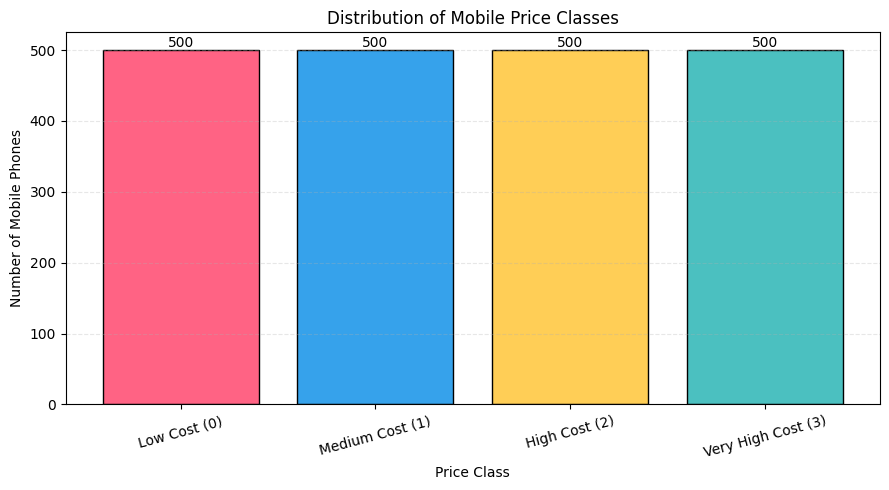

In [ ]:
import matplotlib.pyplot as plt

# Count the number of mobiles in each class
class_counts = data["price_range"].value_counts().sort_index()

# Class names
class_names = [
    "Low Cost (0)",
    "Medium Cost (1)",
    "High Cost (2)",
    "Very High Cost (3)"
]

# Create bar chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    class_names,
    [class_counts.get(i, 0) for i in range(4)],
    color=["#FF6384", "#36A2EB", "#FFCE56", "#4BC0C0"],
    edgecolor="black"
)

plt.title("Distribution of Mobile Price Classes")
plt.xlabel("Price Class")
plt.ylabel("Number of Mobile Phones")
plt.xticks(rotation=15)
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Display count above each bar
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [ ]:

X = data.drop("price_range", axis=1)
y = data["price_range"]

print("Input features:", X.shape)
print("Target values:", y.shape)
print("Price categories:", sorted(y.unique()))


Input features: (2000, 20)
Target values: (2000,)
Price categories: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


Training records: 1600
Testing records: 400

Logistic Regression
Training Accuracy: 97.69 %
Testing Accuracy: 96.5 %

Naive Bayes
Training Accuracy: 81.88 %
Testing Accuracy: 81.0 %


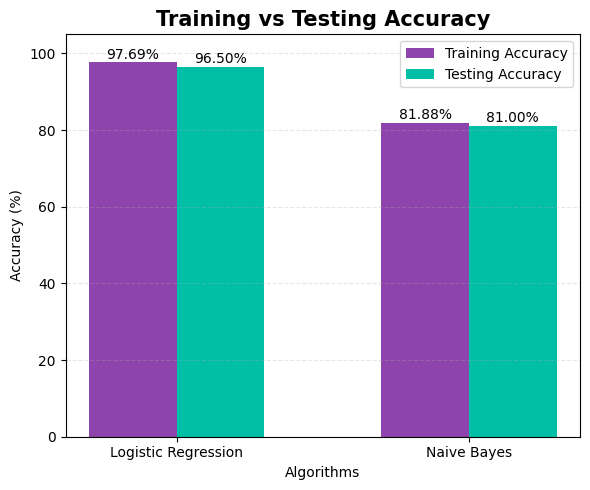

In [ ]:

# SPLIT DATASET INTO TRAINING AND TESTING

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


# TRAIN BOTH ALGORITHMS

lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
lr_model.fit(X_train, y_train)

nb_model = GaussianNB()
nb_model.fit(X_train, y_train)


# CALCULATE TRAINING AND TESTING ACCURACY

lr_train_acc = accuracy_score(
    y_train, lr_model.predict(X_train)
) * 100

lr_test_acc = accuracy_score(
    y_test, lr_model.predict(X_test)
) * 100

nb_train_acc = accuracy_score(
    y_train, nb_model.predict(X_train)
) * 100

nb_test_acc = accuracy_score(
    y_test, nb_model.predict(X_test)
) * 100


# DISPLAY ACCURACY

print("\nLogistic Regression")
print("Training Accuracy:", round(lr_train_acc, 2), "%")
print("Testing Accuracy:", round(lr_test_acc, 2), "%")

print("\nNaive Bayes")
print("Training Accuracy:", round(nb_train_acc, 2), "%")
print("Testing Accuracy:", round(nb_test_acc, 2), "%")


# BAR CHART: TRAINING VS TESTING

import matplotlib.pyplot as plt
import numpy as np

algorithms = ["Logistic Regression", "Naive Bayes"]
training = [lr_train_acc, nb_train_acc]
testing = [lr_test_acc, nb_test_acc]

x = np.arange(len(algorithms))
width = 0.3

plt.figure(figsize=(6, 5))

bars1 = plt.bar(
    x - width / 2, training, width,
    label="Training Accuracy",
    color="#8E44AD"
)

bars2 = plt.bar(
    x + width / 2, testing, width,
    label="Testing Accuracy",
    color="#00BFA6"
)

plt.title("Training vs Testing Accuracy",
          fontsize=15, fontweight="bold")
plt.xlabel("Algorithms")
plt.ylabel("Accuracy (%)")
plt.xticks(x, algorithms)
plt.ylim(0, 105)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 1,
            f"{height:.2f}%",
            ha="center",
            fontsize=10
        )

plt.tight_layout()
plt.show()



In [ ]:

# TRAIN LOGISTIC REGRESSION

lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

lr_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")


# TRAIN NAIVE BAYES

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

print("Naive Bayes trained successfully!")


Logistic Regression trained successfully!
Naive Bayes trained successfully!


In [ ]:

# PERFORMANCE COMPARISON TABLE

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

lr_pred = lr_model.predict(X_test)
nb_pred = nb_model.predict(X_test)

results = pd.DataFrame({
    "Algorithm": ["Logistic Regression", "Naive Bayes"],

    "Accuracy (%)": [
        accuracy_score(y_test, lr_pred) * 100,
        accuracy_score(y_test, nb_pred) * 100
    ],

    "Precision (%)": [
        precision_score(y_test, lr_pred, average="weighted",
                        zero_division=0) * 100,
        precision_score(y_test, nb_pred, average="weighted",
                        zero_division=0) * 100
    ],

    "Recall (%)": [
        recall_score(y_test, lr_pred, average="weighted",
                     zero_division=0) * 100,
        recall_score(y_test, nb_pred, average="weighted",
                     zero_division=0) * 100
    ],

    "F1-Score (%)": [
        f1_score(y_test, lr_pred, average="weighted",
                 zero_division=0) * 100,
        f1_score(y_test, nb_pred, average="weighted",
                 zero_division=0) * 100
    ]
})

results = results.round(2)

print("ALGORITHM PERFORMANCE COMPARISON")
print(results.to_string(index=False))


ALGORITHM PERFORMANCE COMPARISON
          Algorithm  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
Logistic Regression          96.5          96.50        96.5         96.50
        Naive Bayes          81.0          81.13        81.0         81.05


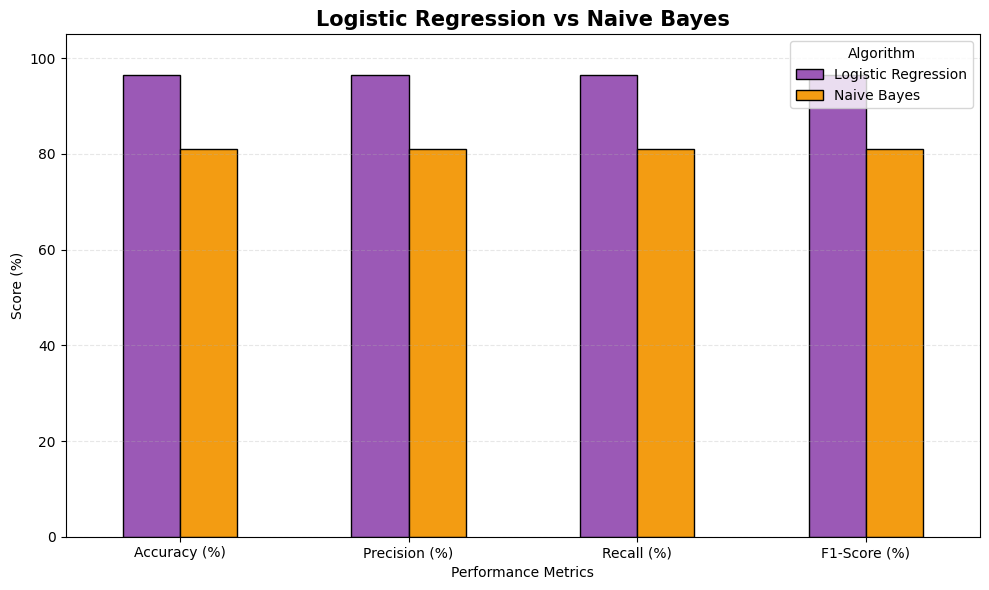

In [ ]:

metrics = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)"
]

results.set_index("Algorithm")[metrics].T.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#9B59B6", "#F39C12"],
    edgecolor="black"
)

plt.title("Logistic Regression vs Naive Bayes",
          fontsize=15, fontweight="bold")
plt.xlabel("Performance Metrics")
plt.ylabel("Score (%)")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.legend(title="Algorithm")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


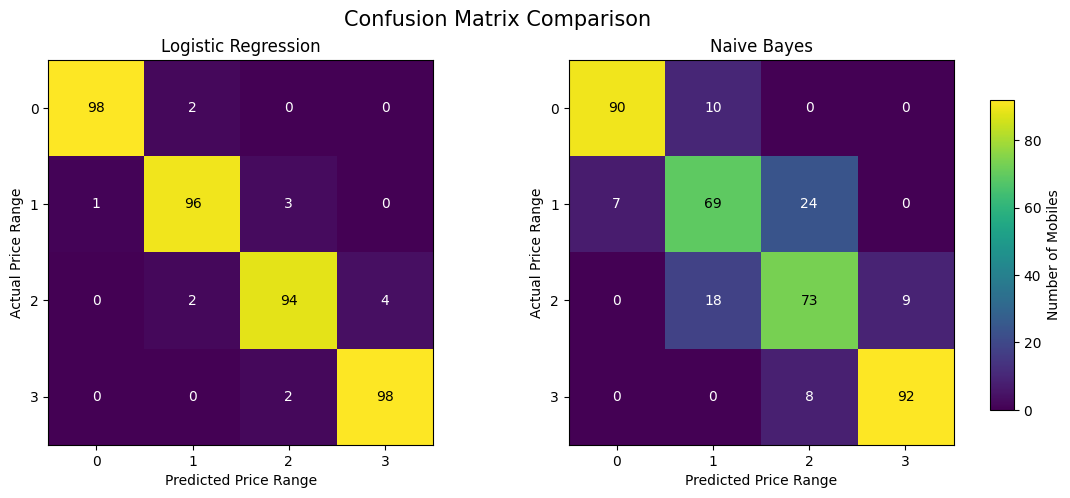

In [ ]:

# CONFUSION MATRIX - FIXED COLOR BAR POSITION

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

lr_pred = lr_model.predict(X_test)
nb_pred = nb_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    (lr_pred, "Logistic Regression", axes[0]),
    (nb_pred, "Naive Bayes", axes[1])
]

for prediction, title, ax in models:
    cm = confusion_matrix(y_test, prediction, labels=[0, 1, 2, 3])

    image = ax.imshow(cm, cmap="viridis")

    ax.set_title(title)
    ax.set_xlabel("Predicted Price Range")
    ax.set_ylabel("Actual Price Range")

    ax.set_xticks([0, 1, 2, 3])
    ax.set_yticks([0, 1, 2, 3])

    for i in range(4):
        for j in range(4):
            color = "white" if cm[i, j] < cm.max() * 0.6 else "black"
            ax.text(j, i, cm[i, j],
                    ha="center", va="center", color=color)

# One shared color bar on the far right
fig.subplots_adjust(right=0.88, wspace=0.35)
cbar_ax = fig.add_axes([0.91, 0.18, 0.02, 0.62])
fig.colorbar(image, cax=cbar_ax, label="Number of Mobiles")

fig.suptitle("Confusion Matrix Comparison", fontsize=15)
plt.show()



ENTER MOBILE DETAILS FOR PREDICTION
Battery Power (mAh): 2000
RAM (MB): 4000
Dual SIM? (1 = Yes, 0 = No): 1
Touchscreen? (1 = Yes, 0 = No): 1
4G Support? (1 = Yes, 0 = No): 1

--- MANUAL PREDICTION RESULTS ---
Logistic Regression: Very High Cost
Naive Bayes: Very High Cost

--- FINAL COMPARISON ---
🏆Logistic Regression performed better in testing accuracy.


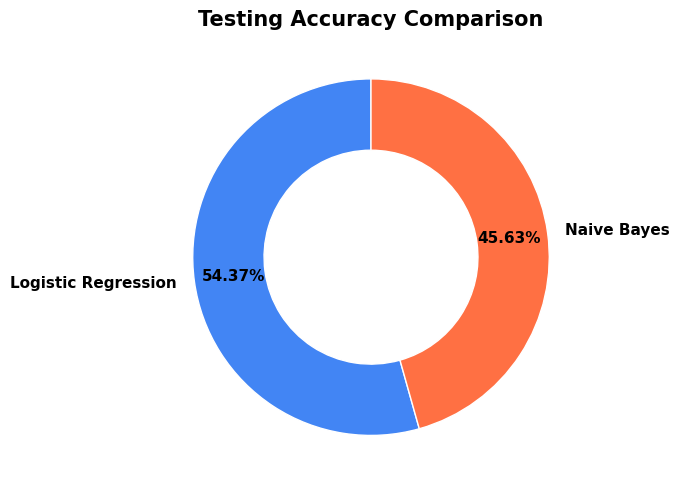

In [ ]:
features = [
    "battery_power",
    "ram",
    "dual_sim",
    "touch_screen",
    "four_g"
]

X_selected = data[features]
y_selected = data["price_range"]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_selected,
    y_selected,
    test_size=0.2,
    random_state=42,
    stratify=y_selected
)

# Train five-feature Logistic Regression
lr_model_s = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
lr_model_s.fit(X_train_s, y_train_s)

# Train five-feature Naive Bayes
nb_model_s = GaussianNB()
nb_model_s.fit(X_train_s, y_train_s)

print("\nENTER MOBILE DETAILS FOR PREDICTION")

battery = float(input("Battery Power (mAh): "))
ram = float(input("RAM (MB): "))
dual_sim = int(input("Dual SIM? (1 = Yes, 0 = No): "))
touch_screen = int(input("Touchscreen? (1 = Yes, 0 = No): "))
four_g = int(input("4G Support? (1 = Yes, 0 = No): "))

new_mobile = pd.DataFrame(
    [[battery, ram, dual_sim, touch_screen, four_g]],
    columns=features
)

lr_result = lr_model_s.predict(new_mobile)[0]
nb_result = nb_model_s.predict(new_mobile)[0]

price_labels = {
    0: "Low Cost",
    1: "Medium Cost",
    2: "High Cost",
    3: "Very High Cost"
}

print("\n--- MANUAL PREDICTION RESULTS ---")
print("Logistic Regression:", price_labels[lr_result])
print("Naive Bayes:", price_labels[nb_result])


# FINAL RESULT

print("\n--- FINAL COMPARISON ---")

if lr_test_acc > nb_test_acc:
    print("🏆Logistic Regression performed better in testing accuracy.")
elif nb_test_acc > lr_test_acc:
    print("🏆Naive Bayes performed better in testing accuracy.")
else:
    print("Both algorithms achieved equal testing accuracy.")

# GRAPH AFTER MANUAL PREDICTION



# COLORFUL DOUGHNUT CHART: ACCURACY COMPARISON

import matplotlib.pyplot as plt

model_names = ["Logistic Regression", "Naive Bayes"]
accuracy_values = [lr_test_acc, nb_test_acc]

plt.figure(figsize=(8, 5))

colors = ["#4285F4", "#FF7043"]

plt.pie(
    accuracy_values,
    labels=model_names,
    colors=colors,
    autopct="%1.2f%%",
    startangle=90,
    pctdistance=0.78,
    wedgeprops={"width": 0.4, "edgecolor": "white"},
    textprops={"fontsize": 11, "weight": "bold"}
)

plt.title(
    "Testing Accuracy Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()
